# Clock drift in the reaction times

Reaction time = wheel movement onset (Arduino clock) - stimulus onset (stimulus computer clock). These sessions have no photodiode onset to align the two clocks. The Arduino clock runs slow, so recorded reaction times are too short, increasingly so through a session.

Times in the data file are in ms.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch

ROOT = Path(sys.executable).parents[2]
sys.path.insert(0, str(ROOT))
from modeling.data import DATA, SESSIONS, STIMS, measure_constants
from modeling.fit import build_model, fit_trials, map_estimate
from modeling.model import GatedDiffusionMixture, GatedDiffusionRace, TaskParams
from modeling.plots import posterior_pairplot, predictive_figure

palette = {"fast": "#E08103", "slow": "#018EC6"}
RECORDED, CORRECTED, RESPONSE = "#898781", "#4A3AA7", "#1BAF7A"     # as recorded, after correction, response time
plt.rcParams["font.family"] = "Helvetica"
np.random.seed(0)
torch.manual_seed(0)

/Users/hayden/Desktop/Desktop/code/goncalves-lab/gated-diffusion-root/ddm-dashboard/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Trials

The 12 sessions of the fit. Every trial with a stimulus is kept, whatever its label.

In [3]:
# stim_type: the short labels of the stimuli (fast, slow). t_reward: Arduino time of the reward. minute: time of stimulus onset since the start of the session
data = (pl.read_parquet(DATA)
    .filter(pl.col("sessiondir").is_in(SESSIONS) & pl.col("contrast").is_not_null())
    .select("sessiondir", "animalid", pl.col("stim_type").replace(STIMS), "contrast", "outcome", "state_outcome", "state_response_time",
            "response_time", "reaction_time", "t_vstimstart", "t_vstimend", "t_vstimstart_rig",
            pl.col("reward").list.get(0, null_on_oob=True).alias("t_reward"))
    .with_columns((pl.col("t_vstimstart") / 60000).alias("minute"))
    .sort("sessiondir", "t_vstimstart"))

print(f"{data.height} trials with a stimulus, {data['t_vstimstart_rig'].is_not_null().sum()} of them with a photodiode onset")

4578 trials with a stimulus, 0 of them with a photodiode onset


### Clock offset

The stimulus computer triggers the reward at stimulus end and the Arduino logs it, so `reward time (Arduino) - stimulus end (stimulus computer)` measures the offset between the clocks on every rewarded trial.

- **Left**: the offset through each session, with one linear fit per session.
- **Right**: the residuals.

┌────────┬──────────┬──────────────────────┬──────────────────────┬────────────────────┬─────────────┬────────────────────┬──────────────────┐
│ animal ┆ rewarded ┆ session length (min) ┆ offset at start (ms) ┆ drift (ms per min) ┆ drift (ppm) ┆ offset at end (ms) ┆ scatter (ms, SD) │
╞════════╪══════════╪══════════════════════╪══════════════════════╪════════════════════╪═════════════╪════════════════════╪══════════════════╡
│ KC139  ┆ 255      ┆ 55.88                ┆ 3.89                 ┆ -2.17              ┆ -36.11      ┆ -117.16            ┆ 1.22             │
│ KC143  ┆ 310      ┆ 89.95                ┆ 6.05                 ┆ -1.59              ┆ -26.45      ┆ -136.71            ┆ 1.39             │
│ KC144  ┆ 320      ┆ 90.04                ┆ 5.07                 ┆ -1.53              ┆ -25.43      ┆ -132.33            ┆ 1.17             │
│ KC145  ┆ 306      ┆ 72.65                ┆ 3.60                 ┆ -2.05              ┆ -34.18      ┆ -145.38            ┆ 1.30             │

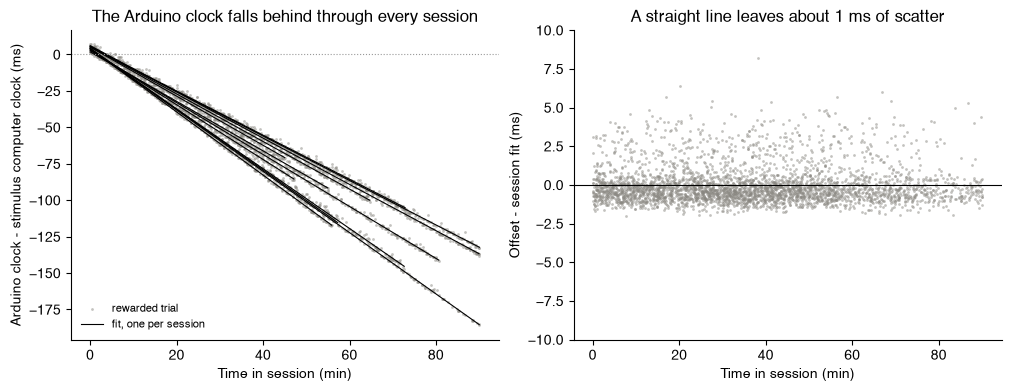

In [4]:
rewarded = (data.filter(pl.col("t_reward").is_not_null())
    .with_columns((pl.col("t_reward") - pl.col("t_vstimend")).alias("offset")))

# one straight line per session: offset (ms) = intercept + slope * minute
rows = []
for session in SESSIONS:
    s = rewarded.filter(pl.col("sessiondir") == session)
    minute, offset = s["minute"].to_numpy(), s["offset"].to_numpy()
    slope, intercept = np.polyfit(minute, offset, 1)
    rows.append(dict(sessiondir=session, animal=s["animalid"][0], rewarded=s.height, minutes=minute.max(),
                     intercept=intercept, slope=slope, at_end=intercept + slope * minute.max(),
                     scatter=np.std(offset - (intercept + slope * minute))))
clock = pl.DataFrame(rows)

rewarded = (rewarded.join(clock.select("sessiondir", "intercept", "slope"), on="sessiondir")
    .with_columns((pl.col("offset") - pl.col("intercept") - pl.col("slope") * pl.col("minute")).alias("residual")))

fig, (ax_offset, ax_residual) = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)
ax_offset.scatter(rewarded["minute"], rewarded["offset"], s=4, color=RECORDED, alpha=0.5, lw=0, label="rewarded trial")
for i, row in enumerate(clock.iter_rows(named=True)):
    minute = np.array([0, row["minutes"]])
    ax_offset.plot(minute, row["intercept"] + row["slope"] * minute, color="k", lw=0.8, label="fit, one per session" if i == 0 else None)
ax_offset.axhline(0, color="0.6", ls=":", lw=0.8)
ax_offset.set(xlabel="Time in session (min)", ylabel="Arduino clock - stimulus computer clock (ms)",
              title="The Arduino clock falls behind through every session")
ax_offset.legend(frameon=False, fontsize=8, loc="lower left")

ax_residual.scatter(rewarded["minute"], rewarded["residual"], s=4, color=RECORDED, alpha=0.5, lw=0)
ax_residual.axhline(0, color="k", lw=0.8)
ax_residual.set(xlabel="Time in session (min)", ylabel="Offset - session fit (ms)", ylim=(-10, 10),
                title="A straight line leaves about 1 ms of scatter")
for ax in (ax_offset, ax_residual):
    ax.spines[["top", "right"]].set_visible(False)

with pl.Config(tbl_rows=20, tbl_width_chars=200, float_precision=2, tbl_hide_dataframe_shape=True, tbl_hide_column_data_types=True):
    print(clock.select("animal", "rewarded", pl.col("minutes").alias("session length (min)"),
                       pl.col("intercept").alias("offset at start (ms)"), pl.col("slope").alias("drift (ms per min)"),
                       (pl.col("slope") / 0.06).alias("drift (ppm)"), pl.col("at_end").alias("offset at end (ms)"),
                       pl.col("scatter").alias("scatter (ms, SD)")))

### Correction

`reaction_time_corrected = reaction_time - (intercept + slope * minute)`

The response time is measured on the stimulus computer alone and needs no correction.

In [5]:
data = (data.join(clock.select("sessiondir", "intercept", "slope"), on="sessiondir")
    .with_columns((pl.col("intercept") + pl.col("slope") * pl.col("minute")).alias("clock_offset"))
    .with_columns((pl.col("reaction_time") - pl.col("clock_offset")).alias("reaction_time_corrected"))
    .sort("sessiondir", "t_vstimstart"))

offset = data.filter(pl.col("outcome") == "hit")["clock_offset"].to_numpy()
print(f"clock offset over the {len(offset)} trials labelled hit: mean {offset.mean():.0f} ms, median {np.median(offset):.0f} ms, "
      f"5th to 95th percentile {np.percentile(offset, 5):.0f} to {np.percentile(offset, 95):.0f} ms")

clock offset over the 3177 trials labelled hit: mean -57 ms, median -55 ms, 5th to 95th percentile -127 to -1 ms


### Check against the response time

Independent of the reward times: the gap between response time (threshold crossing) and reaction time (movement onset) should not change through a session.

Rig hits at 12.5% contrast and above, including those the data file relabels as early. Later bins hold fewer sessions (sessions last 45 to 90 min).

trend of the gap within a session, mean over 12 sessions (range):
  as recorded  +1.81 ms per minute (+1.05 to +3.08)
  corrected    +0.00 ms per minute (-0.73 to +1.40)


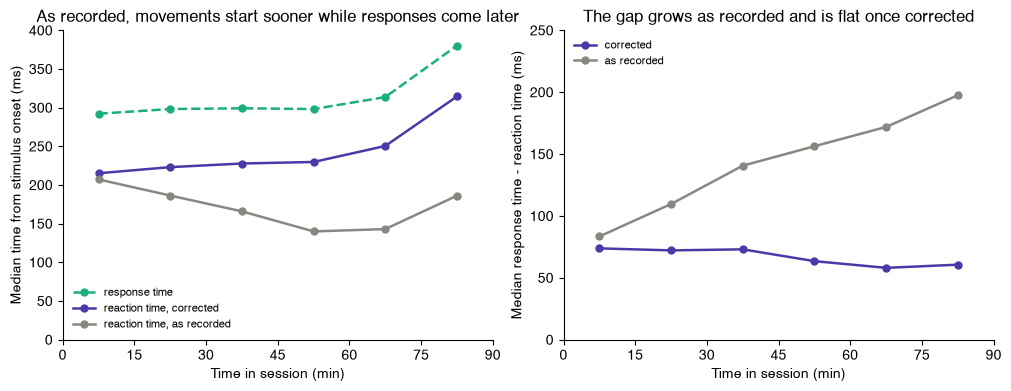

In [6]:
rig_hits = (data.filter((pl.col("state_outcome") == 1) & (pl.col("contrast") >= 0.125) & pl.col("reaction_time").is_not_null())
    .with_columns((pl.col("minute").clip(upper_bound=89.9) // 15 * 15 + 7.5).alias("bin"),
                  (pl.col("response_time") - pl.col("reaction_time")).alias("gap"),
                  (pl.col("response_time") - pl.col("reaction_time_corrected")).alias("gap_corrected")))
binned = (rig_hits.group_by("bin")
    .agg(pl.col("reaction_time", "reaction_time_corrected", "response_time", "gap", "gap_corrected").median(), pl.len().alias("n"))
    .sort("bin"))

fig, (ax_time, ax_gap) = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)
ax_time.plot(binned["bin"], binned["response_time"], "o--", color=RESPONSE, ms=5, lw=1.8, label="response time")
ax_time.plot(binned["bin"], binned["reaction_time_corrected"], "o-", color=CORRECTED, ms=5, lw=1.8, label="reaction time, corrected")
ax_time.plot(binned["bin"], binned["reaction_time"], "o-", color=RECORDED, ms=5, lw=1.8, label="reaction time, as recorded")
ax_time.set(xlabel="Time in session (min)", ylabel="Median time from stimulus onset (ms)", xlim=(0, 90), ylim=(0, 400),
            title="As recorded, movements start sooner while responses come later")
ax_time.legend(frameon=False, fontsize=8, loc="lower left")

ax_gap.plot(binned["bin"], binned["gap_corrected"], "o-", color=CORRECTED, ms=5, lw=1.8, label="corrected")
ax_gap.plot(binned["bin"], binned["gap"], "o-", color=RECORDED, ms=5, lw=1.8, label="as recorded")
ax_gap.set(xlabel="Time in session (min)", ylabel="Median response time - reaction time (ms)", xlim=(0, 90), ylim=(0, 250),
           title="The gap grows as recorded and is flat once corrected")
ax_gap.legend(frameon=False, fontsize=8, loc="upper left")
for ax in (ax_time, ax_gap):
    ax.set_xticks(range(0, 91, 15))
    ax.spines[["top", "right"]].set_visible(False)

# the same check within each session: slope of the gap against time
slopes = np.array([[np.polyfit(s["minute"], s[gap], 1)[0] for gap in ("gap", "gap_corrected")]
                   for s in rig_hits.partition_by("sessiondir")])
print(f"trend of the gap within a session, mean over {len(slopes)} sessions (range):")
for name, values in zip(("as recorded", "corrected"), slopes.T):
    print(f"  {name:12s} {values.mean():+.2f} ms per minute ({values.min():+.2f} to {values.max():+.2f})")

### Reaction times before and after

All rig hits, both stimuli pooled. Dashed line: the 100 ms floor, at or under which the data file relabels a rig hit as early. The floor is applied to the recorded values, so the drift pushes fast hits under it.

┌──────────────┬──────────┬───────────────────────────┬───────────────┬───────────────────────────────────┬────────────────┐
│ contrast (%) ┆ rig hits ┆ under floor: recorded (%) ┆ corrected (%) ┆ median above floor: recorded (ms) ┆ corrected (ms) │
╞══════════════╪══════════╪═══════════════════════════╪═══════════════╪═══════════════════════════════════╪════════════════╡
│ 0.0          ┆ 203      ┆ 21.7                      ┆ 14.8          ┆ 288.8                             ┆ 328.8          │
│ 3.1          ┆ 383      ┆ 8.4                       ┆ 3.9           ┆ 299.8                             ┆ 351.7          │
│ 6.2          ┆ 493      ┆ 5.1                       ┆ 1.2           ┆ 289.0                             ┆ 329.0          │
│ 12.5         ┆ 607      ┆ 5.4                       ┆ 2.3           ┆ 215.5                             ┆ 263.3          │
│ 25.0         ┆ 597      ┆ 12.4                      ┆ 2.2           ┆ 186.8                             ┆ 230.3          │


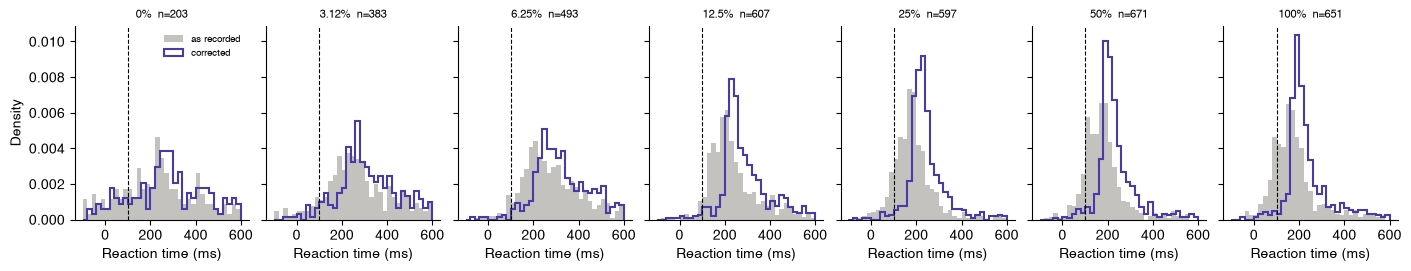

In [7]:
FLOOR = 100                 # ms: rig hits with a reaction time at or under it are early trials

rig_hits = data.filter((pl.col("state_outcome") == 1) & pl.col("reaction_time").is_not_null())
contrasts = np.sort(data["contrast"].unique().to_numpy())
bins = np.arange(-100, 601, 20)

fig, axes = plt.subplots(1, len(contrasts), figsize=(14, 2.6), sharex=True, sharey=True, constrained_layout=True)
for ax, c in zip(axes, contrasts):
    s = rig_hits.filter(pl.col("contrast") == c)
    ax.hist(s["reaction_time"], bins=bins, density=True, color=RECORDED, alpha=0.5, label="as recorded")
    ax.hist(s["reaction_time_corrected"], bins=bins, density=True, histtype="step", color=CORRECTED, lw=1.5, label="corrected")
    ax.axvline(FLOOR, color="k", ls="--", lw=0.8)
    ax.set_title(f"{c * 100:.3g}%  n={s.height}", fontsize=8)
    ax.set_xlabel("Reaction time (ms)")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Density")
axes[0].legend(frameon=False, fontsize=7, loc="upper right")

# share of rig hits at or under the floor, and median reaction time of those above it
under = (rig_hits.group_by((pl.col("contrast") * 100).alias("contrast (%)"))
    .agg(pl.len().alias("rig hits"),
         ((pl.col("reaction_time") <= FLOOR).mean() * 100).alias("under floor: recorded (%)"),
         ((pl.col("reaction_time_corrected") <= FLOOR).mean() * 100).alias("corrected (%)"),
         pl.col("reaction_time").filter(pl.col("reaction_time") > FLOOR).median().alias("median above floor: recorded (ms)"),
         pl.col("reaction_time_corrected").filter(pl.col("reaction_time_corrected") > FLOOR).median().alias("corrected (ms)"))
    .sort("contrast (%)"))
with pl.Config(tbl_rows=20, tbl_width_chars=220, fmt_str_lengths=40, float_precision=1, tbl_hide_dataframe_shape=True, tbl_hide_column_data_types=True):
    print(under)

### Relabel

From the rig's outcome and the corrected reaction time:

- **Rig hit**: a hit if its corrected reaction time is above the floor, otherwise early.
- **Rig miss with a response time under 1000 ms**: early. These are responses the rig aborted just after stimulus onset, independent of the clock drift. `DROP_ABORTED = False` keeps them as misses.
- **Other rig misses**: misses.

Deadline: 1000 ms minus the median gap between response time and corrected reaction time.

In [8]:
DROP_ABORTED = True

rig_hit = pl.col("state_outcome") == 1
aborted = (pl.col("state_outcome") == 0) & (pl.col("state_response_time") < 1000)
data = data.with_columns(
    pl.when(rig_hit & (pl.col("reaction_time_corrected") <= FLOOR)).then(pl.lit("early"))
      .when(rig_hit).then(pl.lit("hit"))
      .when(aborted & DROP_ABORTED).then(pl.lit("early"))
      .otherwise(pl.lit("miss")).alias("outcome_corrected"))

print("labels in the data file (rows) against rebuilt labels (columns):")
with pl.Config(tbl_hide_dataframe_shape=True, tbl_hide_column_data_types=True):
    print(data.group_by("outcome", "outcome_corrected").len().sort("outcome", "outcome_corrected")
          .pivot("outcome_corrected", index="outcome", values="len").fill_null(0))

DEADLINE_RECORDED = TaskParams().deadline       # s, as in gated_diffusion_bayes_5param
gap = data.filter(pl.col("outcome_corrected") == "hit").select(pl.col("response_time") - pl.col("reaction_time_corrected")).to_series()
DEADLINE_CORRECTED = round((1000 - gap.median()) / 1000, 2)
print(f"\nmedian gap between response and corrected reaction time: {gap.median():.0f} ms, so the deadline is {DEADLINE_CORRECTED * 1000:.0f} ms "
      f"(as recorded: {DEADLINE_RECORDED * 1000:.0f} ms)")


# trials for the fit, by the rule of `load_trials`: early trials and hits without a reaction time are dropped,
# and hits at or after the deadline become misses
def fit_trials_table(outcome, reaction_time, deadline):
    trials = (data.filter(pl.col(outcome) != "early")
        .select("animalid", "stim_type", "contrast", (pl.col(outcome) == "hit").alias("hit"), (pl.col(reaction_time) / 1000).alias("rt")))
    no_rt = pl.col("hit") & pl.col("rt").is_null()
    late = pl.col("hit") & (pl.col("rt") >= deadline)
    print(f"{trials.height} trials, dropping {trials.filter(no_rt).height} hits without a reaction time, recoding {trials.filter(late).height} late hits as misses: ", end="")
    trials = (trials.filter(~no_rt)
        .with_columns((pl.col("hit") & ~late).alias("hit"), pl.when(late).then(None).otherwise(pl.col("rt")).alias("rt")))
    print(f"{trials.height} trials, {trials['hit'].sum()} hits")
    return trials


print("\nas recorded: ", end="")
trials_recorded = fit_trials_table("outcome", "reaction_time", DEADLINE_RECORDED)
print("corrected:   ", end="")
trials_corrected = fit_trials_table("outcome_corrected", "reaction_time_corrected", DEADLINE_CORRECTED)

labels in the data file (rows) against rebuilt labels (columns):
┌─────────┬───────┬──────┬──────┐
│ outcome ┆ early ┆ hit  ┆ miss │
╞═════════╪═══════╪══════╪══════╡
│ early   ┆ 130   ┆ 302  ┆ 0    │
│ hit     ┆ 0     ┆ 3177 ┆ 0    │
│ miss    ┆ 73    ┆ 0    ┆ 896  │
└─────────┴───────┴──────┴──────┘

median gap between response and corrected reaction time: 68 ms, so the deadline is 930 ms (as recorded: 870 ms)

as recorded: 4146 trials, dropping 4 hits without a reaction time, recoding 17 late hits as misses: 4142 trials, 3156 hits
corrected:   4375 trials, dropping 4 hits without a reaction time, recoding 16 late hits as misses: 4371 trials, 3459 hits


### Refit

The mixture model of the main fit: `gamma = 2`, gate shapes `= 1`, lapse and ceiling measured from the trials.

- **As recorded**
- **Corrected, `t0` = 50 ms**
- **Corrected, `t0` fitted**

In [9]:
METHOD = "laplace"          # "laplace" (seconds) or "nuts" (minutes)

stims = sorted(palette)


# t0: start of evidence accumulation (s), or None to fit it
# model: GatedDiffusionMixture, or GatedDiffusionRace for the race variant fitted further down
def fit(trials, deadline, t0=0.050, model=GatedDiffusionMixture):
    task = TaskParams(floor=FLOOR / 1000, deadline=deadline)
    stim, contrast = trials["stim_type"].to_numpy().astype(str), trials["contrast"].to_numpy()
    hit, rt = trials["hit"].to_numpy(), trials["rt"].to_numpy()

    # lapse timing, lapse frequency and gate ceiling are measured from the trials, not fitted
    const = measure_constants(trials, task, verbose=False)
    lapse = dict(lapse_dist="invgauss", lapse_tau=const["lapse_tau"], lapse_shape=const["lapse_shape"])

    fixed = {"gamma": 2.0, "shape_fast": 1.0, "shape_slow": 1.0, "ceiling": const["ceiling"], "lapse_prob": const["lapse_prob"]}
    if t0 is not None:
        fixed["t0"] = t0
    posterior = fit_trials(stim, contrast, hit, rt, model, task=task, method=METHOD, fixed=fixed, **lapse)

    # a model built from parameters (name -> value), with the window and the lapse shape used in the fit
    def build(theta):
        return build_model(theta, stims, model, task=task, **lapse)

    at_mean = build(posterior.mean().row(0, named=True))
    return dict(posterior=posterior, model=at_mean, build=build, fitted=[name for name in posterior.columns if name not in fixed],
                log_lik=at_mean.log_likelihood(stim, contrast, hit, rt), trials=trials.height, hits=int(hit.sum()), **const)


fits = {"as recorded": fit(trials_recorded, DEADLINE_RECORDED),
        "corrected, t0 = 50 ms": fit(trials_corrected, DEADLINE_CORRECTED),
        "corrected, t0 fitted": fit(trials_corrected, DEADLINE_CORRECTED, t0=None)}

### Parameters

Posterior mean ± SD. Log-likelihoods are comparable only between fits to the same trials (the two corrected fits).

In [10]:
def cell(f, name, scale=1, digits=3):
    mean, sd = f["posterior"][name].mean() * scale, f["posterior"][name].std(ddof=0) * scale
    return f"{mean:.{digits}f} ± {sd:.{digits}f}" if name in f["fitted"] else f"{mean:.{digits}f} (fixed)"


# one column per fit: fitted parameters, measured values, trial counts and log-likelihood
def show_parameters(fits):
    rows = [("gain", lambda f: cell(f, "gain")),
            ("sigma", lambda f: cell(f, "sigma")),
            ("c50", lambda f: cell(f, "c50")),
            ("scale_fast", lambda f: cell(f, "scale_fast")),
            ("scale_slow", lambda f: cell(f, "scale_slow")),
            ("t0 (ms)", lambda f: cell(f, "t0", 1000, 0)),
            ("ceiling (measured)", lambda f: f"{f['ceiling']:.3f}"),
            ("lapse prob (measured)", lambda f: f"{f['lapse_prob']:.3f}"),
            ("lapse timing: mean (s), shape", lambda f: f"{f['lapse_tau']:.3f}, {f['lapse_shape']:.3f}"),
            ("trials (hits)", lambda f: f"{f['trials']} ({f['hits']})"),
            ("log-likelihood at posterior mean", lambda f: f"{f['log_lik']:.1f}")]
    table = pl.DataFrame({"": [name for name, _ in rows]} | {label: [value(f) for _, value in rows] for label, f in fits.items()})
    with pl.Config(tbl_rows=20, tbl_width_chars=220, fmt_str_lengths=40, tbl_hide_dataframe_shape=True, tbl_hide_column_data_types=True):
        print(table)


show_parameters(fits)
gain = fits["corrected, t0 fitted"]["log_lik"] - fits["corrected, t0 = 50 ms"]["log_lik"]
print(f"\nfitting t0 on the corrected trials raises the log-likelihood by {gain:.1f} for one extra parameter")

┌──────────────────────────────────┬───────────────┬───────────────────────┬──────────────────────┐
│                                  ┆ as recorded   ┆ corrected, t0 = 50 ms ┆ corrected, t0 fitted │
╞══════════════════════════════════╪═══════════════╪═══════════════════════╪══════════════════════╡
│ gain                             ┆ 7.159 ± 0.126 ┆ 5.217 ± 0.061         ┆ 6.035 ± 0.186        │
│ sigma                            ┆ 1.374 ± 0.029 ┆ 0.882 ± 0.017         ┆ 1.098 ± 0.048        │
│ c50                              ┆ 0.072 ± 0.004 ┆ 0.056 ± 0.002         ┆ 0.063 ± 0.003        │
│ scale_fast                       ┆ 0.028 ± 0.004 ┆ 0.042 ± 0.004         ┆ 0.040 ± 0.004        │
│ scale_slow                       ┆ 0.105 ± 0.008 ┆ 0.120 ± 0.008         ┆ 0.118 ± 0.008        │
│ t0 (ms)                          ┆ 50 (fixed)    ┆ 50 (fixed)            ┆ 77 ± 5               │
│ ceiling (measured)               ┆ 0.921         ┆ 0.965                 ┆ 0.965                │


### Posterior: corrected, `t0` fitted

MAP: {'gain': 6.0142, 'sigma': 1.0932, 'c50': 0.0623, 't0': 0.0765, 'scale_fast': 0.04, 'scale_slow': 0.1178} log-likelihood 1536.0


/Users/hayden/Desktop/Desktop/code/goncalves-lab/gated-diffusion-root/ddm-dashboard/.venv/lib/python3.12/site-packages/scipy/stats/_kde.py:741: RuntimeWarning: divide by zero encountered in vecdot
  self._neff = 1/np.vecdot(self.weights, self.weights)
/Users/hayden/Desktop/Desktop/code/goncalves-lab/gated-diffusion-root/ddm-dashboard/.venv/lib/python3.12/site-packages/scipy/stats/_kde.py:741: RuntimeWarning: overflow encountered in vecdot
  self._neff = 1/np.vecdot(self.weights, self.weights)
/Users/hayden/Desktop/Desktop/code/goncalves-lab/gated-diffusion-root/ddm-dashboard/.venv/lib/python3.12/site-packages/scipy/stats/_kde.py:741: RuntimeWarning: invalid value encountered in vecdot
  self._neff = 1/np.vecdot(self.weights, self.weights)


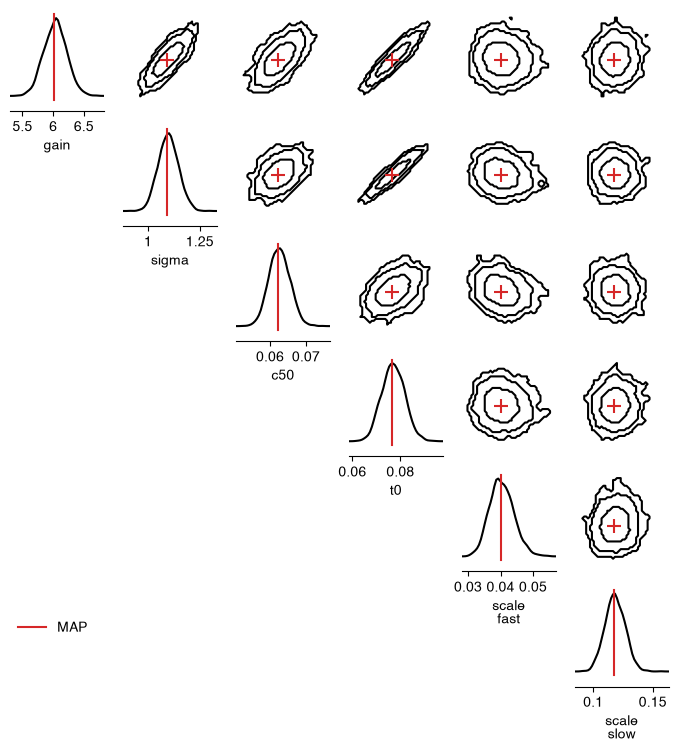

In [11]:
stim, contrast = trials_corrected["stim_type"].to_numpy().astype(str), trials_corrected["contrast"].to_numpy()
hit, rt = trials_corrected["hit"].to_numpy(), trials_corrected["rt"].to_numpy()

PLOT_ORDER = ["gain", "sigma", "c50", "t0", "scale_fast", "scale_slow"]      # diffusion parameters first, then the gate parameters


# pairplot of the fitted parameters of one fit to the corrected trials, with its MAP estimate
def plot_posterior(f):
    plot_order = [name for name in PLOT_ORDER if name in f["fitted"]]
    theta_map, map_log_lik = map_estimate(f["posterior"], f["fitted"], f["build"], stim, contrast, hit, rt)
    print("MAP:", {name: round(theta_map[name], 4) for name in plot_order}, f"log-likelihood {map_log_lik:.1f}")
    return posterior_pairplot(f["posterior"], theta_map, plot_order, figsize=(8.5, 8.5))


fig = plot_posterior(fits["corrected, t0 fitted"])

### Posterior predictive: corrected

Model panels: simulated from the fit with `t0` fitted. Lines: both corrected fits at their posterior means.

reaction time of hits (ms): 10 / 25 / 50 / 75 / 90th percentile
┌──────────┬──────────────┬─────────────────────────────┬─────────────────────────────┐
│ stimulus ┆ contrast (%) ┆ data                        ┆ model, t0 fitted            │
╞══════════╪══════════════╪═════════════════════════════╪═════════════════════════════╡
│ fast     ┆ 12.5         ┆ 201 / 224 / 262 / 347 / 472 ┆ 178 / 211 / 263 / 337 / 428 │
│ fast     ┆ 25.0         ┆ 182 / 198 / 228 / 263 / 356 ┆ 168 / 195 / 237 / 295 / 364 │
│ fast     ┆ 50.0         ┆ 174 / 192 / 212 / 259 / 333 ┆ 165 / 191 / 231 / 284 / 349 │
│ fast     ┆ 100.0        ┆ 166 / 181 / 209 / 266 / 422 ┆ 165 / 190 / 229 / 282 / 345 │
│ slow     ┆ 12.5         ┆ 215 / 233 / 267 / 333 / 466 ┆ 177 / 214 / 271 / 357 / 474 │
│ slow     ┆ 25.0         ┆ 189 / 208 / 236 / 295 / 359 ┆ 168 / 196 / 240 / 301 / 379 │
│ slow     ┆ 50.0         ┆ 183 / 200 / 226 / 277 / 388 ┆ 165 / 191 / 231 / 285 / 351 │
│ slow     ┆ 100.0        ┆ 170 / 190 / 214 / 269 / 393 

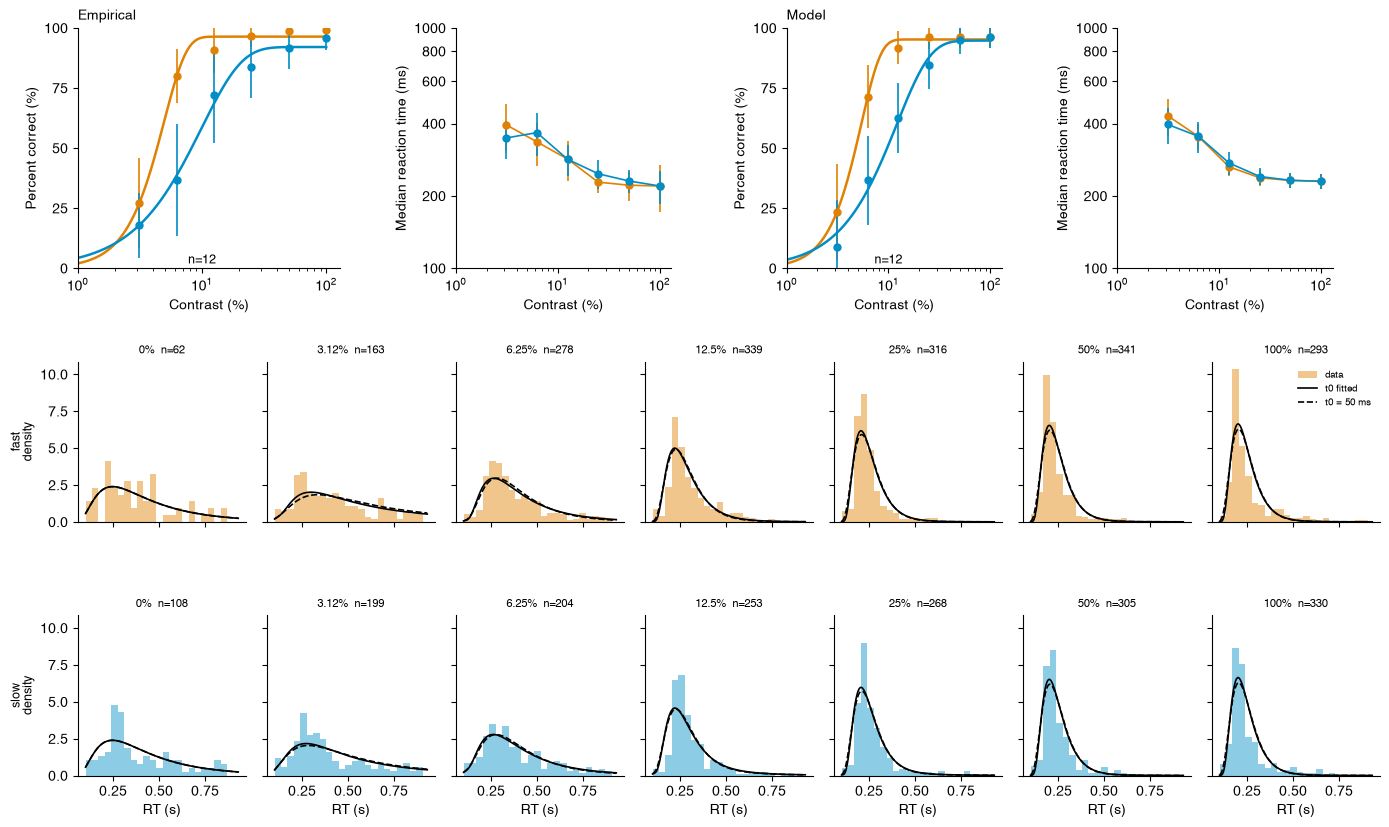

In [12]:
N_SIMS = 200
QUANTILES = [0.1, 0.25, 0.5, 0.75, 0.9]


def hit_rts(stim_type, c):
    return trials_corrected.filter((pl.col("stim_type") == stim_type) & (pl.col("contrast") == c) & pl.col("hit"))["rt"].to_numpy()


# f: the fit simulated in the "Model" panels, one dataset per posterior draw
# lines: {label: (fit, line style)}, the densities drawn in the bottom rows, each at its posterior mean
def plot_predictive(f, lines):
    draws = f["posterior"][np.random.choice(len(f["posterior"]), N_SIMS, replace=False)]
    return predictive_figure(trials_corrected, f["build"], draws, {label: (g["model"], style) for label, (g, style) in lines.items()}, palette)


# reaction-time quantiles of hits at 12.5% contrast and above, data against each fit in {label: fit}
def show_quantiles(fits):
    fmt = lambda q: " / ".join(f"{v * 1000:.0f}" for v in q)
    rows = []
    for stim_type in palette:
        for c in contrasts[contrasts >= 0.125]:
            row = {"stimulus": stim_type, "contrast (%)": c * 100, "data": fmt(np.quantile(hit_rts(stim_type, c), QUANTILES))}
            rows.append(row | {label: fmt(f["model"].rt_quantile(stim_type, np.array([c]), QUANTILES)[:, 0]) for label, f in fits.items()})
    print("reaction time of hits (ms): 10 / 25 / 50 / 75 / 90th percentile")
    with pl.Config(tbl_rows=20, tbl_width_chars=220, fmt_str_lengths=40, tbl_hide_dataframe_shape=True, tbl_hide_column_data_types=True):
        print(pl.DataFrame(rows))


fig = plot_predictive(fits["corrected, t0 fitted"], {"t0 fitted": (fits["corrected, t0 fitted"], "-"), "t0 = 50 ms": (fits["corrected, t0 = 50 ms"], "--")})
show_quantiles({"model, t0 fitted": fits["corrected, t0 fitted"]})

## Race model

Mixture: on a gate-open trial only the evidence process can respond. Race: the lapse process also runs, and whichever finishes first responds. Same parameters, measured values and trials, so the log-likelihoods are comparable.

In [13]:
fits_race = {"mixture, t0 fitted": fits["corrected, t0 fitted"],
             "race, t0 = 50 ms": fit(trials_corrected, DEADLINE_CORRECTED, model=GatedDiffusionRace),
             "race, t0 fitted": fit(trials_corrected, DEADLINE_CORRECTED, t0=None, model=GatedDiffusionRace)}

show_parameters(fits_race)
mixture, race_fixed, race = (f["log_lik"] for f in fits_race.values())
print(f"\nlog-likelihood of the race model minus the mixture model, both with t0 fitted: {race - mixture:+.1f}")
print(f"fitting t0 in the race model raises the log-likelihood by {race - race_fixed:.1f} for one extra parameter")

┌──────────────────────────────────┬────────────────────┬──────────────────┬─────────────────┐
│                                  ┆ mixture, t0 fitted ┆ race, t0 = 50 ms ┆ race, t0 fitted │
╞══════════════════════════════════╪════════════════════╪══════════════════╪═════════════════╡
│ gain                             ┆ 6.035 ± 0.186      ┆ 5.109 ± 0.068    ┆ 8.881 ± 0.267   │
│ sigma                            ┆ 1.098 ± 0.048      ┆ 0.813 ± 0.018    ┆ 1.962 ± 0.078   │
│ c50                              ┆ 0.063 ± 0.003      ┆ 0.065 ± 0.003    ┆ 0.100 ± 0.006   │
│ scale_fast                       ┆ 0.040 ± 0.004      ┆ 0.038 ± 0.004    ┆ 0.035 ± 0.004   │
│ scale_slow                       ┆ 0.118 ± 0.008      ┆ 0.117 ± 0.008    ┆ 0.108 ± 0.008   │
│ t0 (ms)                          ┆ 77 ± 5             ┆ 50 (fixed)       ┆ 140 ± 2         │
│ ceiling (measured)               ┆ 0.965              ┆ 0.965            ┆ 0.965           │
│ lapse prob (measured)            ┆ 0.391        

### Posterior: race, `t0` fitted

MAP: {'gain': 8.8684, 'sigma': 1.9612, 'c50': 0.0997, 't0': 0.14, 'scale_fast': 0.0348, 'scale_slow': 0.1072} log-likelihood 1664.6


/Users/hayden/Desktop/Desktop/code/goncalves-lab/gated-diffusion-root/ddm-dashboard/.venv/lib/python3.12/site-packages/scipy/stats/_kde.py:741: RuntimeWarning: divide by zero encountered in vecdot
  self._neff = 1/np.vecdot(self.weights, self.weights)
/Users/hayden/Desktop/Desktop/code/goncalves-lab/gated-diffusion-root/ddm-dashboard/.venv/lib/python3.12/site-packages/scipy/stats/_kde.py:741: RuntimeWarning: overflow encountered in vecdot
  self._neff = 1/np.vecdot(self.weights, self.weights)
/Users/hayden/Desktop/Desktop/code/goncalves-lab/gated-diffusion-root/ddm-dashboard/.venv/lib/python3.12/site-packages/scipy/stats/_kde.py:741: RuntimeWarning: invalid value encountered in vecdot
  self._neff = 1/np.vecdot(self.weights, self.weights)


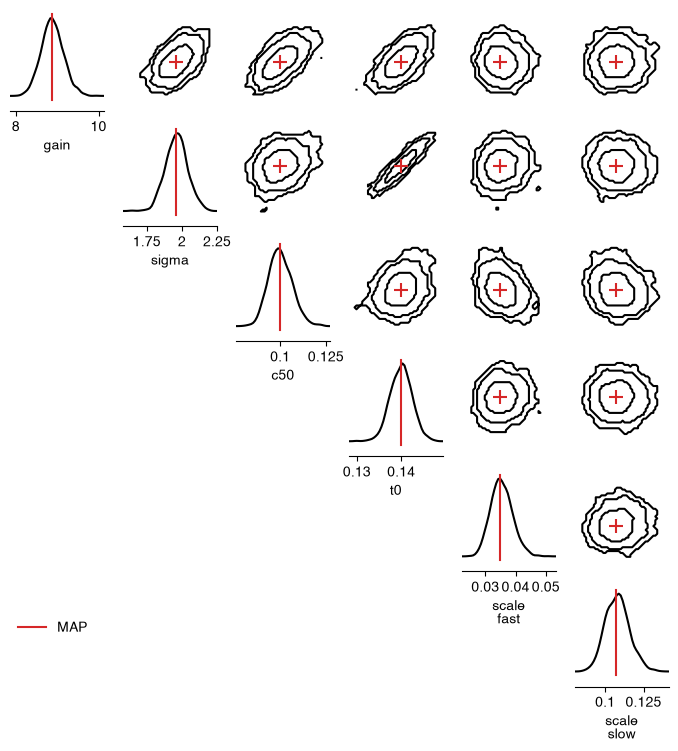

In [14]:
fig = plot_posterior(fits_race["race, t0 fitted"])

### Posterior predictive: race

Model panels: simulated from the race fit. Lines: race (solid) and mixture (dashed), both with `t0` fitted.

reaction time of hits (ms): 10 / 25 / 50 / 75 / 90th percentile
┌──────────┬──────────────┬─────────────────────────────┬─────────────────────────────┬─────────────────────────────┐
│ stimulus ┆ contrast (%) ┆ data                        ┆ race                        ┆ mixture                     │
╞══════════╪══════════════╪═════════════════════════════╪═════════════════════════════╪═════════════════════════════╡
│ fast     ┆ 12.5         ┆ 201 / 224 / 262 / 347 / 472 ┆ 184 / 212 / 262 / 345 / 464 ┆ 178 / 211 / 263 / 337 / 428 │
│ fast     ┆ 25.0         ┆ 182 / 198 / 228 / 263 / 356 ┆ 180 / 201 / 237 / 293 / 370 ┆ 168 / 195 / 237 / 295 / 364 │
│ fast     ┆ 50.0         ┆ 174 / 192 / 212 / 259 / 333 ┆ 178 / 198 / 230 / 279 / 345 ┆ 165 / 191 / 231 / 284 / 349 │
│ fast     ┆ 100.0        ┆ 166 / 181 / 209 / 266 / 422 ┆ 177 / 197 / 228 / 275 / 339 ┆ 165 / 190 / 229 / 282 / 345 │
│ slow     ┆ 12.5         ┆ 215 / 233 / 267 / 333 / 466 ┆ 184 / 214 / 269 / 366 / 506 ┆ 177 / 214 / 271 / 357 

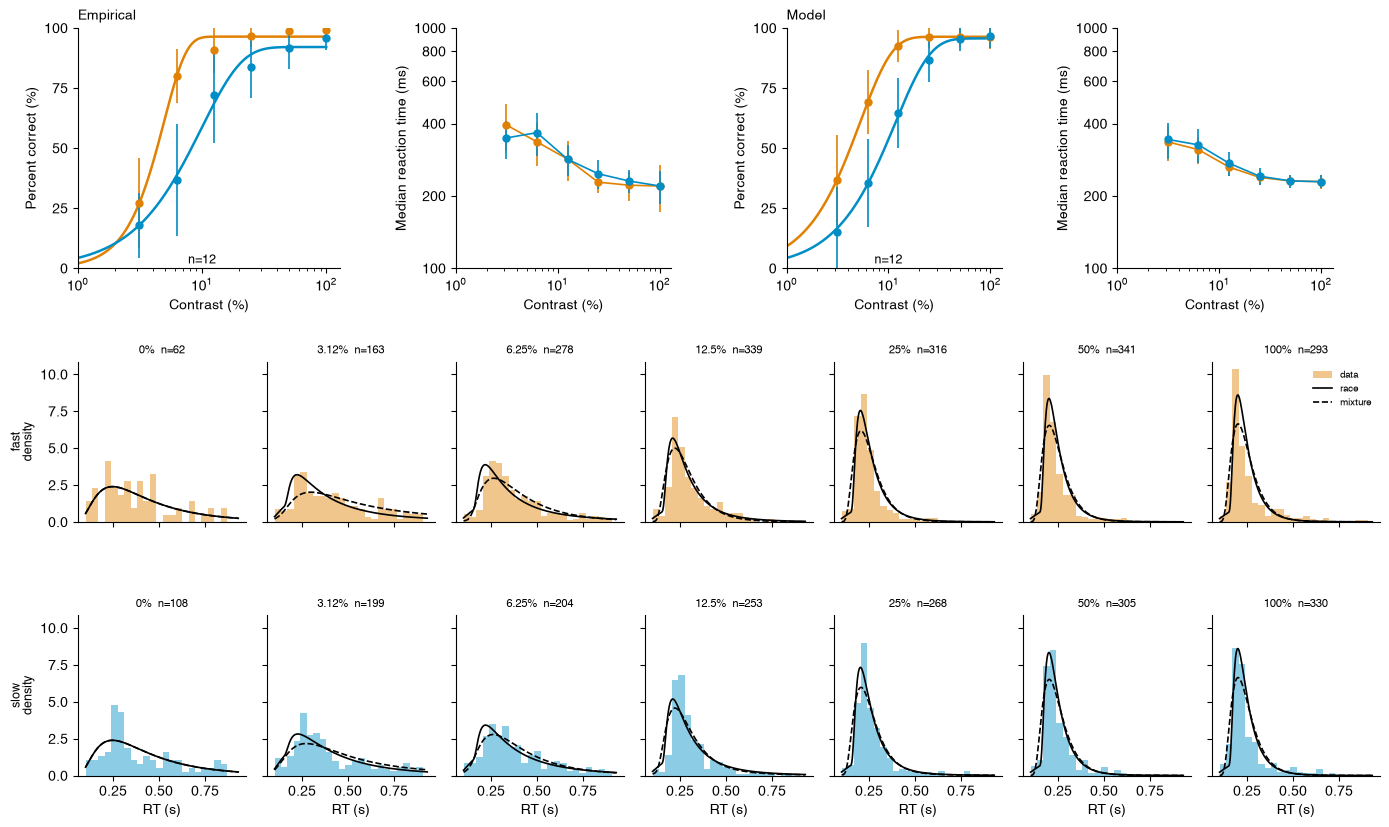

In [15]:
fig = plot_predictive(fits_race["race, t0 fitted"], {"race": (fits_race["race, t0 fitted"], "-"), "mixture": (fits_race["mixture, t0 fitted"], "--")})
show_quantiles({"race": fits_race["race, t0 fitted"], "mixture": fits_race["mixture, t0 fitted"]})

### Caveats

- Corrected reaction times are relative to the stimulus computer's onset time, not to light on the screen. The display delay is constant and is absorbed by `t0`.
- `gamma = 2`, the gate shapes and the lapse form were chosen on the recorded reaction times and are not re-tested here.
- The race model fits high contrast better. At 3.1% and 6.25% it puts a peak near 200 ms that the data do not clearly show, and it overpredicts percent correct at 3.1% for the fast stimulus.
- The race fit puts `t0` above the 100 ms floor, so it attributes the fastest responses on gate-open trials to lapses.